# Mobilidade Urbana Inteligente: modelagem matemática da frota

**Modelagem Matemática e Computacional · Global Solution 2026.2 (CitizenTech)**  
João Guilherme Figueiredo (RM 572697) · Ryan Luther Roque (RM 572993)  
**Equipe:** Citizen Solutions Tech · divisão geral do trabalho: João, códigos e partes complementares; Ryan, lógica e códigos complementares

Os dados do enunciado são hipotéticos. Variáveis: N, S, L e O são os ônibus nos centros Norte, Sul, Leste e Oeste.

A primeira célula de código grava o arquivo `modelo_frota.py` com todo o modelo, para este notebook rodar sozinho.

In [1]:
%%writefile modelo_frota.py
"""Modelagem Matemática e Computacional - GS 2026.2 (CitizenTech).

Mobilidade urbana: recupera a frota por região com um sistema linear (Etapa 1) e
propõe uma redistribuição por transformação linear (Etapa 2).

Execução: python modelo_frota.py   (gera a pasta resultados/)
"""
import json
from fractions import Fraction
from math import ceil
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

RAIZ = Path(__file__).resolve().parent
SAIDA = RAIZ / "resultados"

REGIOES = ["Norte", "Sul", "Leste", "Oeste"]
FROTA_TOTAL = 72
CAPACIDADE = 40
PASSAGEIROS = [560, 760, 720, 840]

# Relatório I. Variáveis na ordem (N, S, L, O); uma linha por registro operacional.
EQUACOES = [
    ("N + S + L + O = 72", [1, 1, 1, 1], 72),
    ("N + 2S + O = 76", [1, 2, 0, 1], 76),
    ("S + 2L = 52", [0, 1, 2, 0], 52),
    ("N + L + 2O = 76", [1, 0, 1, 2], 76),
]


def fmt(v) -> str:
    v = Fraction(v)
    return str(v.numerator) if v.denominator == 1 else f"{v.numerator}/{v.denominator}"


def matriz_str(m) -> list[list[str]]:
    return [[fmt(v) for v in linha] for linha in m]


def eliminar_gauss_jordan(aumentada):
    """Gauss-Jordan com frações exatas. Devolve (matriz final, passos, determinante de A)."""
    m = [[Fraction(v) for v in linha] for linha in aumentada]
    n = len(m)
    det = Fraction(1)
    passos = [{"descricao": "Matriz aumentada [A | b]", "matriz": matriz_str(m)}]
    for c in range(n):
        piv = next((r for r in range(c, n) if m[r][c] != 0), None)
        if piv is None:
            det = Fraction(0)
            continue
        ops = []
        if piv != c:
            m[c], m[piv] = m[piv], m[c]
            det *= -1
            ops.append(f"L{c + 1} <-> L{piv + 1}")
        p = m[c][c]
        det *= p
        if p != 1:
            m[c] = [v / p for v in m[c]]
            ops.append(f"L{c + 1} <- L{c + 1} / {fmt(p)}")
        for r in range(n):
            if r != c and m[r][c] != 0:
                f = m[r][c]
                m[r] = [a - f * b for a, b in zip(m[r], m[c])]
                ops.append(f"L{r + 1} <- L{r + 1} - ({fmt(f)})·L{c + 1}")
        passos.append({"descricao": f"Coluna {c + 1}: " + "; ".join(ops) if ops else f"Coluna {c + 1}: pivô já é 1", "matriz": matriz_str(m)})
    return m, passos, det


def etapa1() -> dict:
    A = [e[1] for e in EQUACOES]
    b = [e[2] for e in EQUACOES]
    aumentada = [linha + [bi] for linha, bi in zip(A, b)]
    final, passos, det = eliminar_gauss_jordan(aumentada)

    posto_A = sum(1 for linha in final if any(v != 0 for v in linha[:4]))
    posto_aug = sum(1 for linha in final if any(v != 0 for v in linha))
    unica = posto_A == posto_aug == len(REGIOES)

    solucao = [final[i][4] for i in range(4)] if unica else None
    x = [int(v) for v in solucao] if unica and all(v.denominator == 1 for v in solucao) else None

    np_A, np_b = np.array(A, float), np.array(b, float)
    conferencia_numpy = np.linalg.solve(np_A, np_b).tolist() if unica else None

    verificacao = []
    if x:
        for texto, coef, rhs in EQUACOES:
            esq = sum(c * xi for c, xi in zip(coef, x))
            verificacao.append({"equacao": texto, "esquerda": esq, "direita": rhs, "ok": esq == rhs})

    return {
        "variaveis": dict(zip(["N", "S", "L", "O"], REGIOES)),
        "equacoes": [{"texto": t, "coeficientes": c, "termo_independente": r} for t, c, r in EQUACOES],
        "A": A,
        "b": b,
        "passos": passos,
        "determinante": fmt(det),
        "determinante_numpy": float(np.linalg.det(np_A)),
        "posto_A": posto_A,
        "posto_aumentada": posto_aug,
        "numero_de_condicao": float(np.linalg.cond(np_A)),
        "solucao_unica": unica,
        "distribuicao_atual": dict(zip(REGIOES, x)) if x else None,
        "x": x,
        "conferencia_numpy": conferencia_numpy,
        "verificacao": verificacao,
        "todas_equacoes_ok": bool(verificacao) and all(v["ok"] for v in verificacao),
    }


def indicadores(x, passageiros=PASSAGEIROS):
    ocupacao = [p / (CAPACIDADE * xi) for p, xi in zip(passageiros, x)]
    nao_atendidos = [max(0, p - CAPACIDADE * xi) for p, xi in zip(passageiros, x)]
    return {
        "onibus": list(x),
        "ocupacao": ocupacao,
        "passageiros_por_onibus": [p / xi for p, xi in zip(passageiros, x)],
        "nao_atendidos": nao_atendidos,
        "total_nao_atendidos": sum(nao_atendidos),
        "ocupacao_maxima": max(ocupacao),
    }


def construir_transformacao(x, necessario, passageiros=PASSAGEIROS):
    """Fluxos guloso: quem mais sobra doa primeiro; quem está mais lotado recebe primeiro."""
    idx = range(len(x))
    saldo = [x[i] - necessario[i] for i in idx]
    doadores = sorted((i for i in idx if saldo[i] > 0), key=lambda i: -saldo[i])
    receptores = sorted((i for i in idx if saldo[i] < 0), key=lambda i: -passageiros[i] / (CAPACIDADE * x[i]))
    sobra = {d: saldo[d] for d in doadores}
    fluxos = []
    for r in receptores:
        falta = -saldo[r]
        for d in doadores:
            q = min(falta, sobra[d])
            if q > 0:
                fluxos.append((d, r, q))
                sobra[d] -= q
                falta -= q
    T = [[Fraction(0)] * len(x) for _ in idx]
    saiu = [0] * len(x)
    for d, r, q in fluxos:
        T[r][d] += Fraction(q, x[d])
        saiu[d] += q
    for j in idx:
        T[j][j] = Fraction(x[j] - saiu[j], x[j])
    return T, fluxos, saldo


def aplicar(T, x):
    return [sum(T[i][j] * x[j] for j in range(len(x))) for i in range(len(x))]


def det_fracao(m):
    _, _, d = eliminar_gauss_jordan([[*linha, 0] for linha in m])
    return d


def etapa2(x) -> dict:
    necessario = [ceil(p / CAPACIDADE) for p in PASSAGEIROS]
    antes = indicadores(x)
    T, fluxos, saldo = construir_transformacao(x, necessario)
    novo_frac = aplicar(T, x)
    novo = [int(v) for v in novo_frac]

    soma_colunas = [sum(T[i][j] for i in range(4)) for j in range(4)]
    menor_coef = min(v for linha in T for v in linha)
    depois = indicadores(novo)

    # Linearidade: T(a·u + b·v) = a·T(u) + b·T(v), testada com vetores quaisquer.
    u, v, a, b = [3, 0, 7, 5], [10, 2, 1, 4], Fraction(2), Fraction(3)
    lhs = aplicar(T, [a * ui + b * vi for ui, vi in zip(u, v)])
    rhs = [a * p + b * q for p, q in zip(aplicar(T, u), aplicar(T, v))]

    return {
        "demanda": [
            {
                "regiao": REGIOES[i],
                "passageiros": PASSAGEIROS[i],
                "capacidade": CAPACIDADE,
                "necessario": necessario[i],
                "atual": x[i],
                "saldo": saldo[i],
            }
            for i in range(4)
        ],
        "total_necessario": sum(necessario),
        "frota_suficiente": sum(necessario) <= FROTA_TOTAL,
        "antes": antes,
        "depois": depois,
        "fluxos": [{"origem": REGIOES[d], "destino": REGIOES[r], "onibus": q} for d, r, q in fluxos],
        "onibus_movidos": sum(q for _, _, q in fluxos),
        "T": matriz_str(T),
        "T_float": [[float(v) for v in linha] for linha in T],
        "novo_vetor": novo,
        "novo_vetor_exato": [fmt(v) for v in novo_frac],
        "soma_das_colunas": [fmt(s) for s in soma_colunas],
        "menor_coeficiente": fmt(menor_coef),
        "total_antes": sum(x),
        "total_depois": sum(novo),
        "total_preservado": sum(novo) == sum(x) and all(s == 1 for s in soma_colunas),
        "sem_alocacao_negativa": menor_coef >= 0 and all(n >= 0 for n in novo),
        "atinge_necessidade": novo == necessario,
        "determinante_T": fmt(det_fracao(T)),
        "linearidade_ok": lhs == rhs,
    }


def grafico_frota(e1, e2, destino: Path) -> None:
    x = np.arange(4)
    fig, ax = plt.subplots(figsize=(7.2, 4))
    larg = 0.27
    ax.bar(x - larg, e2["antes"]["onibus"], larg, label="Atual", color="#9aa5b1")
    ax.bar(x, e2["depois"]["onibus"], larg, label="Após redistribuição", color="#0b6e4f")
    ax.bar(x + larg, [d["necessario"] for d in e2["demanda"]], larg, label="Necessário (demanda/40)", color="#e0a100")
    ax.set_xticks(x, REGIOES)
    ax.set_ylabel("Ônibus")
    ax.set_title("Frota por região: atual, após a política e necessária")
    ax.set_ylim(0, 29)
    ax.legend(loc="upper center", ncol=3, fontsize=8)
    fig.tight_layout()
    fig.savefig(destino, dpi=160)
    plt.close(fig)


def grafico_ocupacao(e2, destino: Path) -> None:
    x = np.arange(4)
    fig, ax = plt.subplots(figsize=(7.2, 4))
    larg = 0.35
    ax.bar(x - larg / 2, [o * 100 for o in e2["antes"]["ocupacao"]], larg, label="Antes", color="#9aa5b1")
    ax.bar(x + larg / 2, [o * 100 for o in e2["depois"]["ocupacao"]], larg, label="Depois", color="#0b6e4f")
    ax.axhline(100, color="#b42318", linewidth=1, linestyle="--", label="Limite de capacidade (100%)")
    ax.set_xticks(x, REGIOES)
    ax.set_ylabel("Ocupação da capacidade (%)")
    ax.set_title("Ocupação da frota no horário de pico")
    ax.set_ylim(0, 140)
    ax.legend(loc="upper center", ncol=3, fontsize=8)
    fig.tight_layout()
    fig.savefig(destino, dpi=160)
    plt.close(fig)


def executar() -> dict:
    SAIDA.mkdir(exist_ok=True)
    e1 = etapa1()
    if not e1["solucao_unica"] or e1["x"] is None:
        raise SystemExit("O sistema não tem solução única inteira; não é possível recuperar a frota.")
    e2 = etapa2(e1["x"])
    grafico_frota(e1, e2, SAIDA / "frota_antes_depois.png")
    grafico_ocupacao(e2, SAIDA / "ocupacao_antes_depois.png")
    resultado = {"etapa1": e1, "etapa2": e2}
    (SAIDA / "resultados.json").write_text(json.dumps(resultado, ensure_ascii=False, indent=2), encoding="utf-8")
    return resultado


def imprimir(res: dict) -> None:
    e1, e2 = res["etapa1"], res["etapa2"]
    print("=== ETAPA 1: distribuição atual ===")
    print("Variáveis: N=Norte, S=Sul, L=Leste, O=Oeste")
    for eq in e1["equacoes"]:
        print("  ", eq["texto"])
    print("det(A) =", e1["determinante"], "| posto(A) =", e1["posto_A"], "| posto([A|b]) =", e1["posto_aumentada"])
    print("Solução única:", e1["solucao_unica"], "->", e1["distribuicao_atual"])
    print("Conferência numpy.linalg.solve:", [round(v, 6) for v in e1["conferencia_numpy"]])
    for v in e1["verificacao"]:
        print(f"  {v['equacao']:<20} {v['esquerda']} == {v['direita']}  {'OK' if v['ok'] else 'FALHOU'}")
    print("\n=== ETAPA 2: política de redistribuição ===")
    for d in e2["demanda"]:
        print(f"  {d['regiao']:<6} demanda {d['passageiros']:>3} -> necessário {d['necessario']:>2} | atual {d['atual']:>2} | saldo {d['saldo']:+d}")
    print("Total necessário:", e2["total_necessario"], "(frota", FROTA_TOTAL, ")")
    print("Fluxos:", [f"{f['origem']}->{f['destino']}: {f['onibus']}" for f in e2["fluxos"]])
    print("Matriz T (linhas: destino N,S,L,O; colunas: origem N,S,L,O):")
    for linha in e2["T"]:
        print("  ", linha)
    print("Soma das colunas:", e2["soma_das_colunas"], "| menor coeficiente:", e2["menor_coeficiente"])
    print("T·x =", e2["novo_vetor"], "| total", e2["total_antes"], "->", e2["total_depois"])
    print("Total preservado:", e2["total_preservado"], "| sem negativos:", e2["sem_alocacao_negativa"], "| atinge a necessidade:", e2["atinge_necessidade"])
    print("det(T) =", e2["determinante_T"], "| linearidade verificada:", e2["linearidade_ok"])
    print("Não atendidos no pico:", e2["antes"]["total_nao_atendidos"], "->", e2["depois"]["total_nao_atendidos"])
    print("Ônibus movidos:", e2["onibus_movidos"], "de", FROTA_TOTAL)


if __name__ == "__main__":
    imprimir(executar())

Overwriting modelo_frota.py


In [2]:
import pandas as pd
from IPython.display import Image, display
import modelo_frota as mf

res = mf.executar()
e1, e2 = res['etapa1'], res['etapa2']

## Etapa 1: diagnóstico da situação atual

### b) e c) Modelo e sistema matricial A·x = b

In [3]:
for eq in e1['equacoes']:
    print(eq['texto'])
print()
print('A =')
display(pd.DataFrame(e1['A'], columns=['N', 'S', 'L', 'O']))
print('b =', e1['b'])

N + S + L + O = 72
N + 2S + O = 76
S + 2L = 52
N + L + 2O = 76

A =


,N,S,L,O
0,1,1,1,1
1,1,2,0,1
2,0,1,2,0
3,1,0,1,2


b = [72, 76, 52, 76]


### d) Unicidade da solução: Gauss-Jordan com frações exatas, posto e determinante

In [4]:
for passo in e1['passos']:
    print(passo['descricao'])
    for linha in passo['matriz']:
        print('   ', linha)
    print()

Matriz aumentada [A | b]
    ['1', '1', '1', '1', '72']
    ['1', '2', '0', '1', '76']
    ['0', '1', '2', '0', '52']
    ['1', '0', '1', '2', '76']

Coluna 1: L2 <- L2 - (1)·L1; L4 <- L4 - (1)·L1
    ['1', '1', '1', '1', '72']
    ['0', '1', '-1', '0', '4']
    ['0', '1', '2', '0', '52']
    ['0', '-1', '0', '1', '4']

Coluna 2: L1 <- L1 - (1)·L2; L3 <- L3 - (1)·L2; L4 <- L4 - (-1)·L2
    ['1', '0', '2', '1', '68']
    ['0', '1', '-1', '0', '4']
    ['0', '0', '3', '0', '48']
    ['0', '0', '-1', '1', '8']

Coluna 3: L3 <- L3 / 3; L1 <- L1 - (2)·L3; L2 <- L2 - (-1)·L3; L4 <- L4 - (-1)·L3
    ['1', '0', '0', '1', '36']
    ['0', '1', '0', '0', '20']
    ['0', '0', '1', '0', '16']
    ['0', '0', '0', '1', '24']

Coluna 4: L1 <- L1 - (1)·L4
    ['1', '0', '0', '0', '12']
    ['0', '1', '0', '0', '20']
    ['0', '0', '1', '0', '16']
    ['0', '0', '0', '1', '24']



In [5]:
print('posto(A)        =', e1['posto_A'])
print('posto([A | b])  =', e1['posto_aumentada'])
print('det(A)          =', e1['determinante'], '(numpy:', round(e1['determinante_numpy'], 4), ')')
print('solução única   =', e1['solucao_unica'])

posto(A)        = 4
posto([A | b])  = 4
det(A)          = 3 (numpy: 3.0 )
solução única   = True


### e) e f) Distribuição encontrada e verificação dos registros

In [6]:
print('Distribuição atual:', e1['distribuicao_atual'])
display(pd.DataFrame(e1['verificacao']))

Distribuição atual: {'Norte': 12, 'Sul': 20, 'Leste': 16, 'Oeste': 24}


,equacao,esquerda,direita,ok
0,N + S + L + O = 72,72,72,True
1,N + 2S + O = 76,76,76,True
2,S + 2L = 52,52,52,True
3,N + L + 2O = 76,76,76,True


## Etapa 2: política de redistribuição

### a) e b) Necessidade e desequilíbrios

Necessidade da região i: n_i = teto(passageiros_i / 40).

In [7]:
display(pd.DataFrame(e2['demanda']))
print('Total necessário:', e2['total_necessario'], '| frota suficiente:', e2['frota_suficiente'])
print('Ocupação antes:', [round(o, 3) for o in e2['antes']['ocupacao']])
print('Passageiros sem vaga antes:', e2['antes']['nao_atendidos'])

,regiao,passageiros,capacidade,necessario,atual,saldo
0,Norte,560,40,14,12,-2
1,Sul,760,40,19,20,1
2,Leste,720,40,18,16,-2
3,Oeste,840,40,21,24,3


Total necessário: 72 | frota suficiente: True
Ocupação antes: [1.167, 0.95, 1.125, 0.875]
Passageiros sem vaga antes: [80, 0, 80, 0]


### c) Política: fluxos entre regiões

Quem tem mais sobra doa primeiro; quem está mais lotado recebe primeiro; só doam as regiões com sobra e só recebem as com falta.

In [8]:
display(pd.DataFrame(e2['fluxos']))
print('Ônibus movidos:', e2['onibus_movidos'])

,origem,destino,onibus
0,Oeste,Norte,2
1,Oeste,Leste,1
2,Sul,Leste,1


Ônibus movidos: 4


### d) e e) Transformação linear T(x) = M·x e a matriz M

m_ij (i ≠ j) é a fração da frota da região j enviada à região i; m_jj é a fração que permanece.

In [9]:
regs = ['Norte', 'Sul', 'Leste', 'Oeste']
M = pd.DataFrame(e2['T'], index=['destino ' + r for r in regs], columns=['origem ' + r for r in regs])
display(M)

,origem Norte,origem Sul,origem Leste,origem Oeste
destino Norte,1,0,0,1/12
destino Sul,0,19/20,0,0
destino Leste,0,1/20,1,1/24
destino Oeste,0,0,0,7/8


### f) Demonstrações: total preservado e nenhuma alocação negativa

Cada coluna de M soma 1 (toda a frota de uma região fica ou é enviada) e todos os coeficientes são não negativos. Logo Σ(Mx)_i = Σ x_j e (Mx)_i ≥ 0 para qualquer x ≥ 0.

In [10]:
print('Soma de cada coluna de M :', e2['soma_das_colunas'])
print('Menor coeficiente de M  :', e2['menor_coeficiente'])
print('M·x                     :', e2['novo_vetor'], '(necessidade:', [d['necessario'] for d in e2['demanda']], ')')
print('Total antes -> depois   :', e2['total_antes'], '->', e2['total_depois'])
print('Total preservado        :', e2['total_preservado'])
print('Sem alocação negativa   :', e2['sem_alocacao_negativa'])
print('Atinge a necessidade    :', e2['atinge_necessidade'])
print('det(M)                  :', e2['determinante_T'])
print('Linearidade verificada  :', e2['linearidade_ok'])

Soma de cada coluna de M : ['1', '1', '1', '1']
Menor coeficiente de M  : 0
M·x                     : [14, 19, 18, 21] (necessidade: [14, 19, 18, 21] )
Total antes -> depois   : 72 -> 72
Total preservado        : True
Sem alocação negativa   : True
Atinge a necessidade    : True
det(M)                  : 133/160
Linearidade verificada  : True


## Resultado da intervenção

Passageiros sem vaga: 160 -> 0
Ocupação máxima: 1.167 -> 1.0


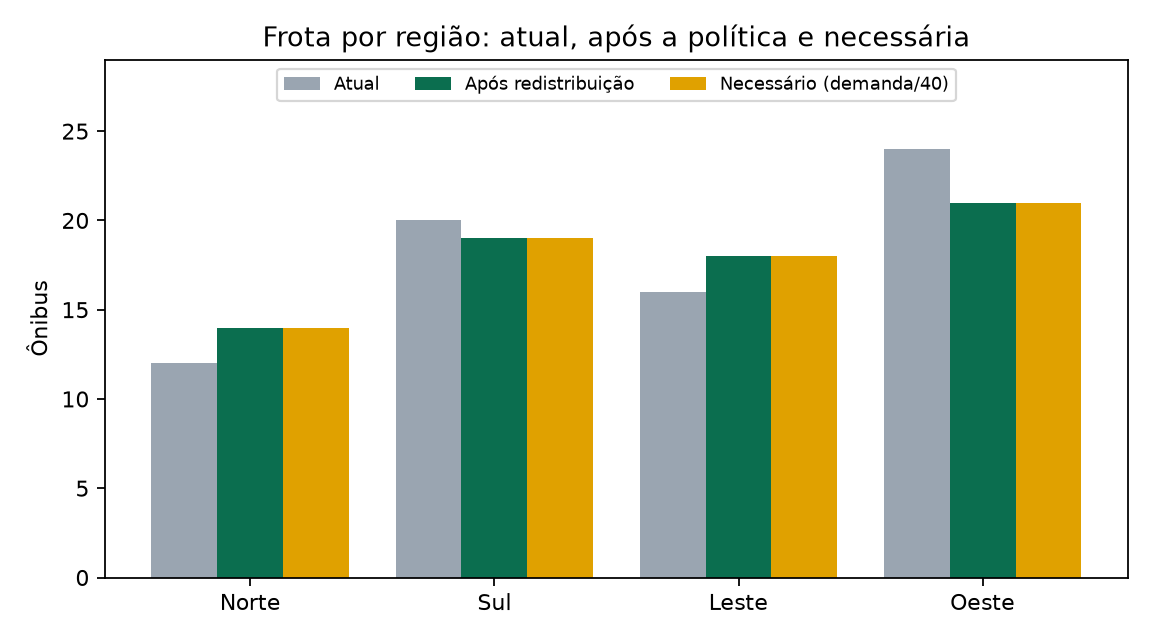

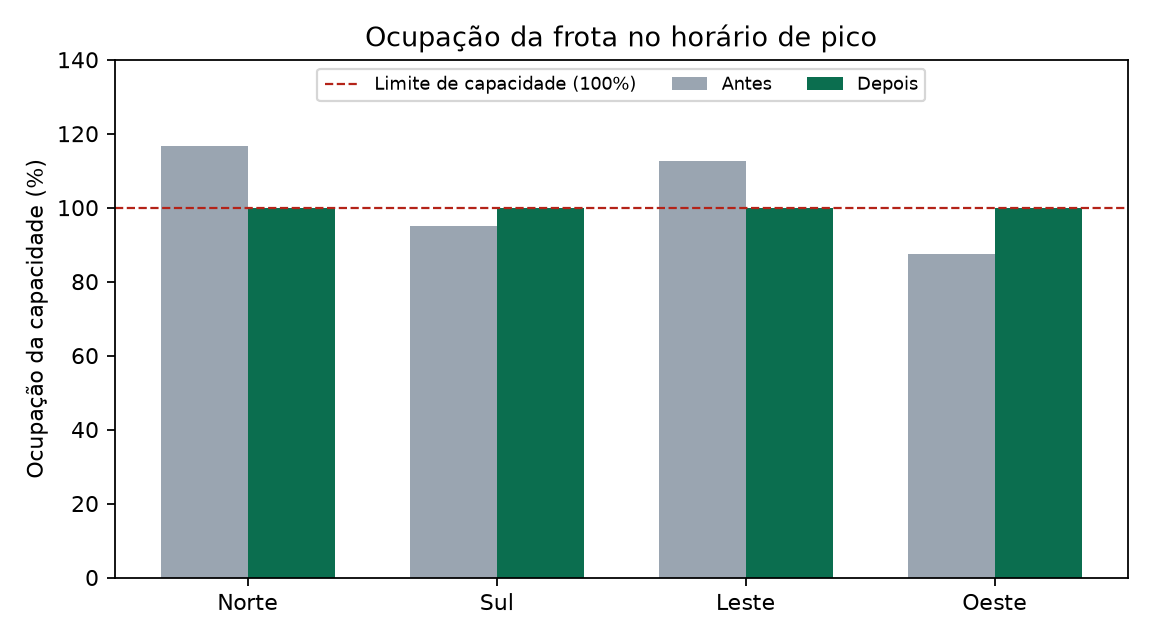

In [11]:
print('Passageiros sem vaga:', e2['antes']['total_nao_atendidos'], '->', e2['depois']['total_nao_atendidos'])
print('Ocupação máxima:', round(e2['antes']['ocupacao_maxima'], 3), '->', round(e2['depois']['ocupacao_maxima'], 3))
display(Image('resultados/frota_antes_depois.png'))
display(Image('resultados/ocupacao_antes_depois.png'))

**Conclusão.** A frota (72) é suficiente para a demanda do pico (72), mas está mal distribuída. Mover 4 ônibus elimina a superlotação de Norte e Leste e a transformação proposta preserva o total e não gera valores negativos. Limitações: dados hipotéticos, um único horário e M calibrada para a distribuição atual.